# ESMFold2 predictions

## Canonical binding

Builds the ESMFold2 input table from the peptide-binding data: every peptide crossed with every
KIR-MHC pair, as sequences (for folding) and as names (for reading).

Sequences come from `KIR_Alleles_tab.txt` (KIR ectodomains, built in `Alignment.ipynb`) and from
`preMSA/Alleles_tab.txt` (B2M). The two HLA-C sequences are **not** in either file and have to be
pasted in below.

In [ ]:
import re
from pathlib import Path

import pandas as pd

PROJ    = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
BINDING = PROJ / "261105_kir_binding_table1_fig2.xlsx"
KIR_TAB = PROJ / "KIR_Alleles_tab.txt"
REF_TAB = Path("/Users/roessner/Documents/PostDoc/Data/preMSA/Alleles_tab.txt")

# each experiment keeps its inputs beside its own predictions, so the two never
# shadow each other despite sharing filenames and the kir_ id prefix
CANON_DIR = PROJ / "esmfold2_canonical_binding"
CANON_DIR.mkdir(exist_ok=True)

KIR_GROUP = "001"   # use the *001 allele of each KIR gene

### MHC naming

`preMSA/Alleles_tab.txt` originally held no HLA-C at all. The two needed alleles were added to it
from IPD-IMGT/HLA (`C*05:01:01:01`, accession HLA00427, and `C*08:02:01:01`, HLA00446), trimmed to
the same construct as every other class-I row: the 24-residue signal peptide removed, then 273
residues of alpha1-alpha3.

Note that HLA-C's mature chain begins **`CSHSMRY`**, with a cysteine where HLA-A and HLA-B have a
glycine (`GSHSMRY`). That is a real difference between the loci, not a transcription error.

So both sequences are now looked up from the file rather than pasted here.

In [ ]:
# spelled as in the tab files, so the names file is a key into them
MHC_NAME = {
    "HLA-C*05:01": "HLA_C0501",
    "HLA-C*08:02": "HLA_C0802",
}

### Read the binding table

The sheet's last row is a `Total` summary (`Sequence` is empty, the columns hold 24/13/11), so it
is dropped - otherwise it becomes a junk combination. That leaves 29 peptides: the NP control plus
28 real ones.

The three data columns are named `<MHC>-<KIR>`, so the pairing is parsed from the header rather
than hardcoded.

In [ ]:
raw = pd.read_excel(BINDING)

table = raw[raw.Peptide.ne("Total") & raw.Sequence.notna()].copy()

PAIR_RE = re.compile(r"^(?P<mhc>HLA-\S+?)-(?P<kir>KIR\w+)$")
pairs = {col: (m.group("mhc"), m.group("kir"))
         for col in raw.columns
         if (m := PAIR_RE.match(str(col)))}
assert pairs, "no <MHC>-<KIR> columns found - check the sheet header"

print(f"{len(table)} peptides x {len(pairs)} pairs = {len(table) * len(pairs)} rows")
for col, (mhc, kir) in pairs.items():
    print(f"  {col:24s} ->  MHC {mhc:12s} KIR {kir}")
table.head()

### Look up every sequence

All four chains come from the two tab files, so nothing is hardcoded here.

In [ ]:
kir_tab = pd.read_csv(KIR_TAB, sep="\t")
ref_tab = pd.read_csv(REF_TAB, sep="\t")

kir_seq = dict(zip(kir_tab.Allele, kir_tab.seq))
ref_seq = dict(zip(ref_tab.Allele, ref_tab.seq))

B2M_SEQ = ref_seq["B2M"]

kir_lookup = {}
for mhc, kir in pairs.values():
    key = f"{kir}_{KIR_GROUP}"
    if key not in kir_seq:
        raise KeyError(f"{key} not in {KIR_TAB.name}")
    kir_lookup[kir] = {"name": key, "seq": kir_seq[key]}

MHC_SEQ = {}
for mhc in {m for m, _ in pairs.values()}:
    name = MHC_NAME[mhc]
    if name not in ref_seq:
        raise KeyError(f"{name} not in {REF_TAB.name}")
    MHC_SEQ[mhc] = ref_seq[name]

for kir, d in kir_lookup.items():
    print(f"  {d['name']:14s} {len(d['seq']):3d} aa  {d['seq'][:34]}...")
for mhc, s in sorted(MHC_SEQ.items()):
    print(f"  {MHC_NAME[mhc]:14s} {len(s):3d} aa  {s[:34]}...")
print(f"  {'B2M':14s} {len(B2M_SEQ):3d} aa  {B2M_SEQ[:34]}...")

### Build every peptide x pair combination

The NP control carries the literal text `no peptide` in the sheet; it becomes an empty `PEPTIDE`
field, giving exactly one empty-peptide row per KIR-MHC pair.

`binds` keeps the 0/1 from the sheet. It is not written to either output file, since those have a
fixed column set, but it is here to filter or label with.

In [ ]:
rows = []
for col, (mhc, kir) in pairs.items():
    for _, r in table.iterrows():
        peptide = "" if str(r["Sequence"]).strip().lower() == "no peptide" else r["Sequence"]
        rows.append({
            "KIR_name":   kir_lookup[kir]["name"],
            "MHC_name":   mhc,
            "B2M_name":   "B2M",
            "PEPTIDE":    peptide,
            "peptide_id": r["Peptide"],
            "binds":      int(r[col]),
        })

combos = pd.DataFrame(rows)
combos.insert(0, "ID", [f"kir_{i:04d}" for i in range(1, len(combos) + 1)])

assert combos.ID.is_unique
assert (combos.PEPTIDE == "").sum() == len(pairs)

print(f"{len(combos)} rows, {combos.ID.iloc[0]} .. {combos.ID.iloc[-1]}; "
      f"{int(combos.binds.sum())} binding")
combos.head()

### The names file

Same rows and same IDs as the sequence file, with the allele names in place of the sequences, so
the two join on `ID`. The peptide stays as its sequence; `combos.peptide_id` holds the `P2` / `NP`
labels if you would rather key on those.

Names are written exactly as the tab files spell them - `KIR2DL1_001`, `HLA_C0501`, `B2M` - so
every value here is a key into `KIR_Alleles_tab.txt` or `Alleles_tab.txt` rather than a second
naming scheme.

`BINDING` carries the 0/1 from the sheet, so this file doubles as the label table to score the
folding results against. The sequence file is left at the five chain columns.

In [ ]:
names = pd.DataFrame({
    "ID":      combos.ID,
    "KIR":     combos.KIR_name,
    "MHC":     combos.MHC_name.map(MHC_NAME),
    "B2M":     "B2M",
    "PEPTIDE": combos.PEPTIDE,
    "BINDING": combos.binds,   # 0/1 straight from the sheet
})

# every name must resolve in the file it claims to come from
assert set(names.KIR) <= set(kir_seq), "a KIR name is not in KIR_Alleles_tab.txt"
assert set(names.MHC) | {"B2M"} <= set(ref_seq), "an MHC name is not in Alleles_tab.txt"

names_path = CANON_DIR / "kir_pmhc_names.csv"
names.to_csv(names_path, index=False)
print(f"wrote {names_path.relative_to(PROJ)}: {len(names)} rows")
names.head()

### The sequence file

Same rows and IDs as the names file, with the sequences substituted in.

In [ ]:
kir_by_name = {d["name"]: d["seq"] for d in kir_lookup.values()}

seqs = pd.DataFrame({
    "ID":      combos.ID,
    "KIR":     combos.KIR_name.map(kir_by_name),
    "MHC":     combos.MHC_name.map(MHC_SEQ),
    "B2M":     B2M_SEQ,
    "PEPTIDE": combos.PEPTIDE,
})

for col in ["KIR", "MHC", "B2M"]:
    assert seqs[col].notna().all() and (seqs[col] != "").all(), f"{col} sequence missing"
assert (seqs.PEPTIDE == "").sum() == len(pairs), "expected one no-peptide row per pair"
assert (seqs.ID == names.ID).all(), "row order differs from the names file"

seqs_path = CANON_DIR / "kir_pmhc_sequences.csv"
seqs.to_csv(seqs_path, index=False)
print(f"wrote {seqs_path.relative_to(PROJ)}: {len(seqs)} rows")
seqs.assign(**{c: seqs[c].str[:26] + "..." for c in ["KIR", "MHC", "B2M"]}).head()

### ESMFold2 results

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

PROJ = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
ESM  = PROJ / "esmfold2_canonical_binding"

METRIC  = "iptm_pair_mean"
DROP_NP = True     # the no-peptide control is a control, not a non-binder

order = ["non-binder", "binder"]
pal   = {"non-binder": "#6f6e6a", "binder": "#2a78d6"}

labels = pd.read_csv(ESM / "kir_pmhc_names.csv", keep_default_na=False)
pred   = pd.read_csv(ESM / "output.csv")

# average over seeds / samples first, so there is exactly one row per complex
pred = pred.groupby("ID", as_index=False).agg(
    **{METRIC: (METRIC, "mean"), "n_pred": (METRIC, "size")})

df = labels.merge(pred, on="ID", how="inner", validate="one_to_one")
assert len(df) == len(labels), f"{len(labels) - len(df)} complexes have no prediction"

df["complex"] = df.KIR.str.replace("_001", "", regex=False) + " / " + df.MHC
df["group"]   = np.where(df.BINDING.eq(1), "binder", "non-binder")
df["is_np"]   = df.PEPTIDE.eq("")

print(f"{df.n_pred.min()}-{df.n_pred.max()} prediction(s) per complex")
df.groupby(["complex", "group"])[METRIC].agg(["count", "mean", "median"])

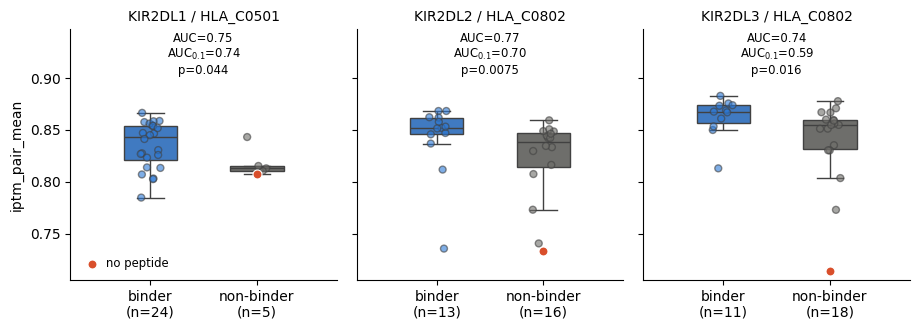

In [5]:
NP_COLOR = "#d94f2b"
order = ["binder", "non-binder"]
pal   = {"binder": "#2a78d6", "non-binder": "#6f6e6a"}

complexes = sorted(df["complex"].unique())

fig, axes = plt.subplots(1, len(complexes), figsize=(3.1 * len(complexes), 3.4),
                         sharey=True)

for i, (ax, cx) in enumerate(zip(np.atleast_1d(axes), complexes)):
    d = df[df["complex"] == cx]

    # the control is a non-binder here, so it is in the box and in the stats;
    # only its marker is pulled out of the strip and redrawn in red on top
    sns.boxplot(d, x="group", y=METRIC, order=order, hue="group", palette=pal,
                width=0.5, showfliers=False, legend=False, ax=ax)
    sns.stripplot(d[~d.is_np], x="group", y=METRIC, order=order, hue="group",
                  palette=pal, jitter=True, alpha=0.6, marker="o", linewidth=1,
                  legend=False, ax=ax)

    npc = d[d.is_np]
    if len(npc):
        ax.scatter([order.index("non-binder")], [npc[METRIC].iat[0]],
                   s=42, marker="o", color=NP_COLOR, edgecolor="white",
                   linewidth=0.8, zorder=6,
                   label="no peptide" if i == 0 else None)

    ax.set_title(cx, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(METRIC if i == 0 else "")
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{g}\n(n={int((d.group == g).sum())})" for g in order])

    # AUC and standardized partial AUC (FPR<=0.1); binder = positive, higher ipTM = better
    y = d.group.eq("binder").astype(int)
    if y.nunique() < 2:
        auc = auc01 = p = np.nan
    else:
        auc   = roc_auc_score(y, d[METRIC])
        auc01 = roc_auc_score(y, d[METRIC], max_fpr=0.1)
        p     = mannwhitneyu(d.loc[y.eq(1), METRIC], d.loc[y.eq(0), METRIC],
                             alternative="greater").pvalue
    txt = f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}\np={p:.2g}"

    # axes coordinates, so the shared y-limit set below does not move the label
    ax.text(0.5, 0.99, txt, transform=ax.transAxes, ha="center", va="top", fontsize="small")

# one shared y-limit, with headroom for the annotations
ax0 = np.atleast_1d(axes)[0]
ymin, ymax = ax0.get_ylim()
ax0.set_ylim(ymin, ymax + 0.30 * (ymax - ymin))
ax0.legend(loc="lower left", frameon=False, fontsize="small", handletextpad=0.2)

sns.despine(fig=fig)
fig.tight_layout()

## Cross-reactivity
KIR2DL2 and KIR2DL3 (C1-KIRs) against HLA-C*05:01 (C2)

### Input preparation

The same build as the canonical section, against `261109_kir_binding_table1_fig3.xlsx`: the two
C1-restricted KIRs, 2DL2 and 2DL3, on the C2 ligand HLA-C\*05:01.

The logic is identical, so it is written once as `build_inputs()` and could be used for the
canonical table too. The function re-reads both allele tabs itself, so this section runs without
the cells above.

Both experiments write `kir_pmhc_names.csv` and `kir_pmhc_sequences.csv` with `kir_0001`-style
IDs. **The directory is the only thing that tells them apart**, so each one lives beside its own
predictions and neither file nor ID is ever ambiguous within a directory.

In [ ]:
import re
from pathlib import Path

import pandas as pd

PROJ      = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
KIR_TAB   = PROJ / "KIR_Alleles_tab.txt"
REF_TAB   = Path("/Users/roessner/Documents/PostDoc/Data/preMSA/Alleles_tab.txt")
KIR_GROUP = "001"

MHC_NAME = {
    "HLA-C*05:01": "HLA_C0501",
    "HLA-C*08:02": "HLA_C0802",
}

PAIR_RE = re.compile(r"^(?P<mhc>HLA-\S+?)-(?P<kir>KIR\w+)$")


def build_inputs(xlsx, out_dir, kir_group=KIR_GROUP):
    """Every peptide x KIR-MHC pair in `xlsx`, written as names and as sequences.

    Writes kir_pmhc_names.csv and kir_pmhc_sequences.csv into `out_dir`, which is
    what keeps one experiment's inputs from shadowing another's. Returns the two
    frames: same rows, same IDs, joinable on ID.
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(exist_ok=True)

    kir_seq = dict(pd.read_csv(KIR_TAB, sep="\t")[["Allele", "seq"]].itertuples(index=False))
    ref_seq = dict(pd.read_csv(REF_TAB, sep="\t")[["Allele", "seq"]].itertuples(index=False))
    b2m = ref_seq["B2M"]

    raw   = pd.read_excel(xlsx)
    table = raw[raw.Peptide.ne("Total") & raw.Sequence.notna()].copy()

    pairs = {col: (m.group("mhc"), m.group("kir"))
             for col in raw.columns if (m := PAIR_RE.match(str(col)))}
    assert pairs, f"no <MHC>-<KIR> columns in {Path(xlsx).name} - check the sheet header"

    rows = []
    for col, (mhc, kir) in pairs.items():
        kir_name = f"{kir}_{kir_group}"
        mhc_name = MHC_NAME[mhc]
        if kir_name not in kir_seq:
            raise KeyError(f"{kir_name} not in {KIR_TAB.name}")
        if mhc_name not in ref_seq:
            raise KeyError(f"{mhc_name} not in {REF_TAB.name}")
        for _, r in table.iterrows():
            peptide = "" if str(r["Sequence"]).strip().lower() == "no peptide" else r["Sequence"]
            rows.append({"KIR": kir_name, "MHC": mhc_name, "B2M": "B2M",
                         "PEPTIDE": peptide, "peptide_id": r["Peptide"],
                         "BINDING": int(r[col])})

    combos = pd.DataFrame(rows)
    combos.insert(0, "ID", [f"kir_{i:04d}" for i in range(1, len(combos) + 1)])
    assert combos.ID.is_unique
    assert (combos.PEPTIDE == "").sum() == len(pairs), "expected one no-peptide row per pair"

    names = combos[["ID", "KIR", "MHC", "B2M", "PEPTIDE", "BINDING"]]
    seqs  = pd.DataFrame({
        "ID":      combos.ID,
        "KIR":     combos.KIR.map(kir_seq),
        "MHC":     combos.MHC.map(ref_seq),
        "B2M":     b2m,
        "PEPTIDE": combos.PEPTIDE,
    })
    for c in ["KIR", "MHC", "B2M"]:
        assert seqs[c].notna().all() and (seqs[c] != "").all(), f"{c} sequence missing"
    assert (seqs.ID == names.ID).all()

    names.to_csv(out_dir / "kir_pmhc_names.csv", index=False)
    seqs.to_csv(out_dir / "kir_pmhc_sequences.csv", index=False)

    print(f"{len(table)} peptides x {len(pairs)} pairs = {len(combos)} rows, "
          f"{int(combos.BINDING.sum())} binding")
    for col, (mhc, kir) in pairs.items():
        n = int(combos.loc[combos.KIR.eq(f"{kir}_{kir_group}"), "BINDING"].sum())
        print(f"  {col:24s} ->  {MHC_NAME[mhc]} / {kir}_{kir_group}   {n} binding")
    print(f"wrote kir_pmhc_names.csv and kir_pmhc_sequences.csv to {out_dir.name}/")
    return names, seqs

Run it on the fig-3 table. The printed per-pair counts should match that sheet's own `Total` row,
which is the one check the file carries on itself.

In [ ]:
XR_BINDING = PROJ / "261109_kir_binding_table1_fig3.xlsx"
XR_DIR     = PROJ / "esmfold2_cross_reactivity"

xr_names, xr_seqs = build_inputs(XR_BINDING, XR_DIR)
xr_names.head()

The peptide panel should be the same 29 as the canonical run, since the point of the comparison is
the ligand, not the peptides. Checked rather than assumed.

In [ ]:
CANON_DIR = PROJ / "esmfold2_canonical_binding"
canon = pd.read_csv(CANON_DIR / "kir_pmhc_names.csv", keep_default_na=False)

same = set(canon.PEPTIDE) == set(xr_names.PEPTIDE)
print(f"same peptide panel as the canonical run: {same}")
if not same:
    print("  only canonical:", sorted(set(canon.PEPTIDE) - set(xr_names.PEPTIDE)))
    print("  only cross-reactivity:", sorted(set(xr_names.PEPTIDE) - set(canon.PEPTIDE)))

# the ID spaces now overlap by design, so make sure nothing is joining across them
assert set(canon.ID) & set(xr_names.ID), "expected the two runs to share the kir_ id space"
print(f"ids overlap ({len(set(canon.ID) & set(xr_names.ID))} shared) - "
      f"never merge the two label files without keying on the directory too")

print(f"\n{len(xr_seqs)} complexes to fold, "
      f"{xr_seqs.KIR.str.len().add(xr_seqs.MHC.str.len()).add(xr_seqs.B2M.str.len()).add(xr_seqs.PEPTIDE.str.len()).mean():.0f} aa on average")
xr_seqs.assign(**{c: xr_seqs[c].str[:26] + "..." for c in ["KIR", "MHC", "B2M"]}).head()

### ESMFold2 results

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

PROJ   = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
METRIC = "iptm_pair_mean"
LIGAND = "HLA_C0501"

RUNS = {"canonical":      PROJ / "esmfold2_canonical_binding",
        "cross-reactive": PROJ / "esmfold2_cross_reactivity"}


def load_run(esm_dir, run):
    """Labels joined to predictions, tagged with the run they came from."""
    labels = pd.read_csv(esm_dir / "kir_pmhc_names.csv", keep_default_na=False)
    pred   = pd.read_csv(esm_dir / "output.csv").groupby("ID", as_index=False).agg(
        **{METRIC: (METRIC, "mean"), "n_pred": (METRIC, "size")})
    d = labels.merge(pred, on="ID", how="inner", validate="one_to_one")
    assert len(d) == len(labels), f"{esm_dir.name}: {len(labels) - len(d)} without a prediction"
    d.insert(0, "run", run)
    return d


# both runs number their complexes kir_0001 onward, so the ID alone is ambiguous
# once they are stacked; run + ID is the key
both = pd.concat([load_run(p, run) for run, p in RUNS.items()], ignore_index=True)
assert both.set_index(["run", "ID"]).index.is_unique

xr = both[both.MHC.eq(LIGAND)].copy()
xr["complex"] = xr.KIR.str.replace("_001", "", regex=False) + " / " + xr.MHC
xr["group"]   = np.where(xr.BINDING.eq(1), "binder", "non-binder")
xr["is_np"]   = xr.PEPTIDE.eq("")

print(f"{xr.n_pred.min()}-{xr.n_pred.max()} prediction(s) per complex")
xr.groupby(["complex", "run", "group"])[METRIC].agg(["count", "mean", "median"])

1-1 prediction(s) per complex


count      mean   median
complex             run            group                               
KIR2DL1 / HLA_C0501 canonical      binder         24  0.835354  0.84305
                                   non-binder      5  0.817760  0.81290
KIR2DL2 / HLA_C0501 cross-reactive binder          5  0.850480  0.85290
                                   non-binder     24  0.828654  0.83215
KIR2DL3 / HLA_C0501 cross-reactive binder          5  0.856000  0.85980
                                   non-binder     24  0.834154  0.83755

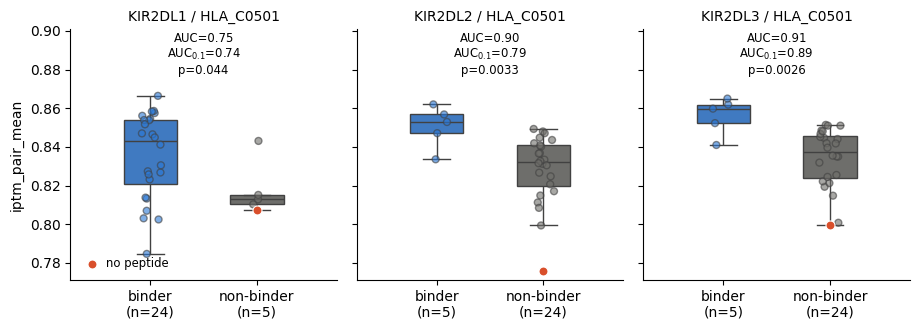

In [7]:
NP_COLOR = "#d94f2b"
order = ["binder", "non-binder"]
pal   = {"binder": "#2a78d6", "non-binder": "#6f6e6a"}

complexes = sorted(xr["complex"].unique())

fig, axes = plt.subplots(1, len(complexes), figsize=(3.1 * len(complexes), 3.4),
                         sharey=True)

for i, (ax, cx) in enumerate(zip(np.atleast_1d(axes), complexes)):
    d = xr[xr["complex"] == cx]

    # the control is a non-binder here, so it is in the box and in the stats;
    # only its marker is pulled out of the strip and redrawn in red on top
    sns.boxplot(d, x="group", y=METRIC, order=order, hue="group", palette=pal,
                width=0.5, showfliers=False, legend=False, ax=ax)
    sns.stripplot(d[~d.is_np], x="group", y=METRIC, order=order, hue="group",
                  palette=pal, jitter=True, alpha=0.6, marker="o", linewidth=1,
                  legend=False, ax=ax)

    npc = d[d.is_np]
    if len(npc):
        ax.scatter([order.index("non-binder")], [npc[METRIC].iat[0]],
                   s=42, marker="o", color=NP_COLOR, edgecolor="white",
                   linewidth=0.8, zorder=6,
                   label="no peptide" if i == 0 else None)

    ax.set_title(cx, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(METRIC if i == 0 else "")
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{g}\n(n={int((d.group == g).sum())})" for g in order])

    # AUC and standardized partial AUC (FPR<=0.1); binder = positive, higher ipTM = better
    y = d.group.eq("binder").astype(int)
    if y.nunique() < 2:
        auc = auc01 = p = np.nan
    else:
        auc   = roc_auc_score(y, d[METRIC])
        auc01 = roc_auc_score(y, d[METRIC], max_fpr=0.1)
        p     = mannwhitneyu(d.loc[y.eq(1), METRIC], d.loc[y.eq(0), METRIC],
                             alternative="greater").pvalue
    txt = f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}\np={p:.2g}"

    # axes coordinates, so the shared y-limit set below does not move the label
    ax.text(0.5, 0.99, txt, transform=ax.transAxes, ha="center", va="top", fontsize="small")

# one shared y-limit, with headroom for the annotations
ax0 = np.atleast_1d(axes)[0]
ymin, ymax = ax0.get_ylim()
ax0.set_ylim(ymin, ymax + 0.30 * (ymax - ymin))
ax0.legend(loc="lower left", frameon=False, fontsize="small", handletextpad=0.2)

sns.despine(fig=fig)
fig.tight_layout()

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

PROJ   = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
METRIC = "iptm_pair_mean"
LIGAND = "HLA_C0501"

RUNS = {"canonical":      PROJ / "esmfold2_canonical_binding",
        "cross-reactive": PROJ / "esmfold2_cross_reactivity"}


def load_run(esm_dir, run):
    """Labels joined to predictions, tagged with the run they came from."""
    labels = pd.read_csv(esm_dir / "kir_pmhc_names.csv", keep_default_na=False)
    pred   = pd.read_csv(esm_dir / "output.csv").groupby("ID", as_index=False).agg(
        **{METRIC: (METRIC, "mean"), "n_pred": (METRIC, "size")})
    d = labels.merge(pred, on="ID", how="inner", validate="one_to_one")
    assert len(d) == len(labels), f"{esm_dir.name}: {len(labels) - len(d)} without a prediction"
    d.insert(0, "run", run)
    return d


# both runs number their complexes kir_0001 onward, so the ID alone is ambiguous
# once they are stacked; run + ID is the key
both = pd.concat([load_run(p, run) for run, p in RUNS.items()], ignore_index=True)
assert both.set_index(["run", "ID"]).index.is_unique

c5 = both[both.MHC.eq(LIGAND)].copy()
c5["kir"]   = c5.KIR.str.replace("_001", "", regex=False)
c5["group"] = np.where(c5.BINDING.eq(1), "binder", "non-binder")
c5["is_np"] = c5.PEPTIDE.eq("")

print(f"{len(c5)} complexes on {LIGAND}, {int(c5.BINDING.sum())} binding")
c5.groupby(["kir", "run", "group"]).size()

87 complexes on HLA_C0501, 34 binding


kir      run             group     
KIR2DL1  canonical       binder        24
                         non-binder     5
KIR2DL2  cross-reactive  binder         5
                         non-binder    24
KIR2DL3  cross-reactive  binder         5
                         non-binder    24
dtype: int64

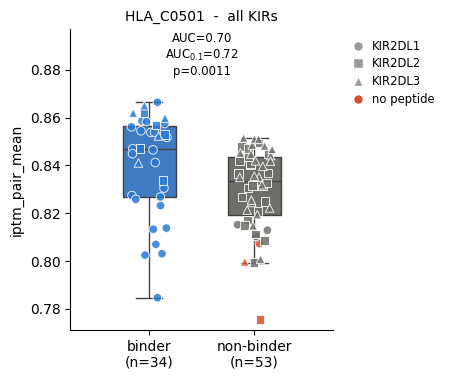

In [5]:
NP_COLOR = "#d94f2b"
order  = ["binder", "non-binder"]
pal    = {"binder": "#2a78d6", "non-binder": "#6f6e6a"}
MARKER = {"KIR2DL1": "o", "KIR2DL2": "s", "KIR2DL3": "^"}
JITTER = 0.17

fig, ax = plt.subplots(figsize=(4.6, 3.9))

sns.boxplot(c5, x="group", y=METRIC, order=order, hue="group", palette=pal,
            width=0.5, showfliers=False, legend=False, ax=ax)

# scatter by hand: seaborn cannot vary the marker within one strip, and the
# marker is what carries the KIR here
rng = np.random.default_rng(0)        # seeded, so the figure is reproducible
for kir, g in c5.groupby("kir"):
    x = np.array([order.index(v) for v in g.group], float)
    x = x + rng.uniform(-JITTER, JITTER, len(x))
    face = [NP_COLOR if np_ else pal[grp] for np_, grp in zip(g.is_np, g.group)]
    ax.scatter(x, g[METRIC], marker=MARKER[kir], s=38, c=face,
               alpha=0.85, linewidth=0.7, edgecolor="white", zorder=5)

ax.set_xlabel("")
ax.set_ylabel(METRIC)
ax.set_title(f"{LIGAND}  -  all KIRs", fontsize=10)
ax.set_xlim(-0.75, 1.75)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{g}\n(n={int((c5.group == g).sum())})" for g in order])

y = c5.group.eq("binder").astype(int)
auc   = roc_auc_score(y, c5[METRIC])
auc01 = roc_auc_score(y, c5[METRIC], max_fpr=0.1)
p     = mannwhitneyu(c5.loc[y.eq(1), METRIC], c5.loc[y.eq(0), METRIC],
                     alternative="greater").pvalue
ax.text(0.5, 0.99, f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}\np={p:.2g}",
        transform=ax.transAxes, ha="center", va="top", fontsize="small")

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin, ymax + 0.26 * (ymax - ymin))

handles = [Line2D([], [], marker=MARKER[k], color="none", markerfacecolor="#9b9a96",
                  markeredgecolor="white", markersize=7, label=k)
           for k in sorted(MARKER) if k in set(c5.kir)]
handles.append(Line2D([], [], marker="o", color="none", markerfacecolor=NP_COLOR,
                      markeredgecolor="white", markersize=7, label="no peptide"))
# outside the axes: 87 points leave no empty corner to sit in
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
          frameon=False, fontsize="small", handletextpad=0.2, labelspacing=0.4)

sns.despine(fig=fig)
fig.tight_layout()

## Bw4 vs Bw6 (no peptide)

### Input preparation

Four KIR3DL1 ectodomains against 25 HLA class-I ligands, **peptide-free**, every combination:
4 x 25 = 100 complexes.

This is a different question from the two sections above. There the ligand was fixed and the
peptide varied; here the peptide is gone and the **ligand** varies, so what is being asked is
whether ipTM separates the Bw4 motif from Bw6 when nothing is in the groove.

Three label columns rather than one:

- `BINDING`  - 0/1, as before
- `LIGAND_GROUP` - `Bw4` or `Bw6`, the serological motif

The two are not redundant. `Bw4` contains one non-binder (B\*13:02), which is the only row that
makes the motif and the phenotype separable at all, and `Bw6` is uniformly non-binding. So
`LIGAND_GROUP` is the structural hypothesis and `BINDING` is the observation.

**`KIR3DL1_015` is deliberately absent.** It is not in `KIR_Alleles_tab.txt`: its ectodomain is
identical to that of 13 other 3-digit groups, and `KIR3DL1_007` was kept as the representative of
that set. Over residues 22-340, which is all that is folded here, *007 and *015 are the same
protein, so *007 stands in for it.

**B\*51:01 and A\*23:01 are excluded**, as artefacts discussed in the source paper. B\*51:01 is in
the reference tab file, A\*23:01 is not. Neither is in the table below, so nothing silently
depends on that decision.

In [ ]:
from pathlib import Path

import pandas as pd

PROJ    = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
KIR_TAB = PROJ / "KIR_Alleles_tab.txt"
REF_TAB = Path("/Users/roessner/Documents/PostDoc/Data/preMSA/Alleles_tab.txt")
BW_DIR  = PROJ / "esmfold2_bw4_bw6"

# *015 is not in the tab file - its ectodomain is identical to *007's, which
# represents that set. See the note above.
KIRS = ["KIR3DL1_001", "KIR3DL1_002", "KIR3DL1_007", "KIR3DL1_008"]

# (paper spelling, Bw4/Bw6, binds 0/1), in the order the ligands are to appear.
# The tab-file name is derived from the spelling rather than written twice, so a
# typo in either one shows up as a KeyError instead of a silent mismatch.
LIGANDS = [
    # Bw4, binding
    ("HLA-B*27:05", "Bw4", 1),
    ("HLA-B*37:01", "Bw4", 1),
    ("HLA-B*44:02", "Bw4", 1),
    ("HLA-B*44:03", "Bw4", 1),
    ("HLA-B*47:01", "Bw4", 1),
    ("HLA-B*38:01", "Bw4", 1),
    ("HLA-B*49:01", "Bw4", 1),
    ("HLA-B*52:01", "Bw4", 1),
    ("HLA-B*53:01", "Bw4", 1),
    ("HLA-B*57:01", "Bw4", 1),
    ("HLA-B*58:01", "Bw4", 1),
    ("HLA-A*24:02", "Bw4", 1),
    ("HLA-A*32:01", "Bw4", 1),
    # Bw4, non-binding
    ("HLA-B*13:02", "Bw4", 0),
    # Bw6, non-binding
    ("HLA-B*07:02", "Bw6", 0),
    ("HLA-B*08:01", "Bw6", 0),
    ("HLA-B*14:02", "Bw6", 0),
    ("HLA-B*15:01", "Bw6", 0),
    ("HLA-B*18:01", "Bw6", 0),
    ("HLA-B*35:01", "Bw6", 0),
    ("HLA-B*40:02", "Bw6", 0),
    ("HLA-B*41:01", "Bw6", 0),
    ("HLA-B*42:01", "Bw6", 0),
    ("HLA-B*45:01", "Bw6", 0),
    ("HLA-B*46:01", "Bw6", 0),
]


def tab_name(spelling):
    """'HLA-B*27:05' -> 'HLA_B2705', the spelling Alleles_tab.txt uses."""
    locus, allele = spelling.removeprefix("HLA-").split("*")
    return f"HLA_{locus}{allele.replace(':', '')}"


print(f"{len(KIRS)} KIR x {len(LIGANDS)} HLA = {len(KIRS) * len(LIGANDS)} complexes")
for grp in ["Bw4", "Bw6"]:
    sub = [(n, b) for n, g, b in LIGANDS if g == grp]
    print(f"  {grp}: {len(sub):2d} ligands, {sum(b for _, b in sub)} binding")

Both allele tabs are read here rather than reused from the sections above, so this section runs on
its own. Every name is resolved before anything is written: a ligand that is not in the reference
file raises, which is what keeps a missing sequence from becoming a silently dropped row.

In [ ]:
kir_seq = dict(pd.read_csv(KIR_TAB, sep="\t")[["Allele", "seq"]].itertuples(index=False))
ref_seq = dict(pd.read_csv(REF_TAB, sep="\t")[["Allele", "seq"]].itertuples(index=False))
B2M_SEQ = ref_seq["B2M"]

missing_kir = [k for k in KIRS if k not in kir_seq]
missing_mhc = [tab_name(s) for s, _, _ in LIGANDS if tab_name(s) not in ref_seq]
assert not missing_kir, f"not in {KIR_TAB.name}: {missing_kir}"
assert not missing_mhc, f"not in {REF_TAB.name}: {missing_mhc}"

for k in KIRS:
    print(f"  {k:14s} {len(kir_seq[k]):3d} aa  {kir_seq[k][:30]}...")
print()
mhc_len = {tab_name(s): len(ref_seq[tab_name(s)]) for s, _, _ in LIGANDS}
print(f"  {len(mhc_len)} MHC, {sorted(set(mhc_len.values()))} aa")
print(f"  {'B2M':14s} {len(B2M_SEQ):3d} aa")

### Build every combination

KIR-major order: all 25 ligands for *001, then for *002, and so on, with the ligands in the order
given above. So the ID runs with the ligand and blocks by KIR, which makes a 4 x 25 reshape of the
results trivial later.

`PEPTIDE` is empty on every row. That is the point of the section, so it is asserted rather than
left to inspection.

In [ ]:
BW_DIR.mkdir(exist_ok=True)

rows = [{"KIR": kir, "MHC": tab_name(spelling), "B2M": "B2M", "PEPTIDE": "",
         "BINDING": binds, "LIGAND_GROUP": group, "MHC_spelled": spelling}
        for kir in KIRS                      # KIR-major, so the blocks are contiguous
        for spelling, group, binds in LIGANDS]

combos = pd.DataFrame(rows)
combos.insert(0, "ID", [f"kir_{i:04d}" for i in range(1, len(combos) + 1)])

assert combos.ID.is_unique
assert len(combos) == len(KIRS) * len(LIGANDS)
assert (combos.PEPTIDE == "").all(), "this section is peptide-free by construction"
assert not combos.duplicated(["KIR", "MHC"]).any(), "a KIR x MHC pair appears twice"

names = combos[["ID", "KIR", "MHC", "B2M", "PEPTIDE", "BINDING", "LIGAND_GROUP"]]
seqs  = pd.DataFrame({
    "ID":      combos.ID,
    "KIR":     combos.KIR.map(kir_seq),
    "MHC":     combos.MHC.map(ref_seq),
    "B2M":     B2M_SEQ,
    "PEPTIDE": combos.PEPTIDE,
})

for c in ["KIR", "MHC", "B2M"]:
    assert seqs[c].notna().all() and (seqs[c] != "").all(), f"{c} sequence missing"
assert (seqs.ID == names.ID).all(), "row order differs from the names file"

names.to_csv(BW_DIR / "kir_pmhc_names.csv", index=False)
seqs.to_csv(BW_DIR / "kir_pmhc_sequences.csv", index=False)
print(f"wrote kir_pmhc_names.csv and kir_pmhc_sequences.csv to {BW_DIR.name}/")
print(f"{len(names)} complexes, {int(names.BINDING.sum())} binding, "
      f"{seqs.KIR.str.len().add(seqs.MHC.str.len()).add(len(B2M_SEQ)).mean():.0f} aa on average")
names.head()

### Checks

The label table should be balanced the same way for every KIR, since the ligand panel is identical
across them. A cross-tab is the quickest way to see that, and it also shows the one asymmetry that
matters: `Bw4` is 13 binders to 1 non-binder, so the Bw4-internal comparison rests on a single
negative and will not support an AUC on its own. The usable contrast is Bw4-binding against the
11 Bw6 ligands.

In [ ]:
print(pd.crosstab([names.LIGAND_GROUP, names.BINDING], names.KIR), end="\n\n")

# the ID space collides with the other two runs by design; the directory is the key
for other in ["esmfold2_canonical_binding", "esmfold2_cross_reactivity"]:
    o = pd.read_csv(PROJ / other / "kir_pmhc_names.csv", keep_default_na=False)
    print(f"  ids shared with {other}: {len(set(o.ID) & set(names.ID))}"
          f" of {len(names)} - key on the directory, never on ID alone")

# ligand order preserved, and the KIR blocks contiguous
assert list(names.MHC[:len(LIGANDS)]) == [tab_name(s) for s, _, _ in LIGANDS]
assert list(names.KIR.unique()) == KIRS
print(f"\nfirst block: {names.ID.iat[0]}-{names.ID.iat[len(LIGANDS) - 1]} = {KIRS[0]}")
print(f"last block:  {names.ID.iat[-len(LIGANDS)]}-{names.ID.iat[-1]} = {KIRS[-1]}")
seqs.assign(**{c: seqs[c].str[:24] + "..." for c in ["KIR", "MHC", "B2M"]}).head()

### ESMFold2 results

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

PROJ   = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
ESM    = PROJ / "esmfold2_bw4_bw6"
METRIC = "iptm_pair_mean"

labels = pd.read_csv(ESM / "kir_pmhc_names.csv", keep_default_na=False)
pred   = pd.read_csv(ESM / "output.csv")

# average over seeds / samples first, so there is exactly one row per complex
pred = pred.groupby("ID", as_index=False).agg(
    **{METRIC: (METRIC, "mean"), "n_pred": (METRIC, "size")})

bw = labels.merge(pred, on="ID", how="inner", validate="one_to_one")
assert len(bw) == len(labels), f"{len(labels) - len(bw)} complexes have no prediction"

# panels are the KIR allele; the ligand group is deliberately ignored here
bw["kir"]   = bw.KIR.str.replace("KIR3DL1_", "*", regex=False)
bw["group"] = np.where(bw.BINDING.eq(1), "binder", "non-binder")

print(f"{bw.n_pred.min()}-{bw.n_pred.max()} prediction(s) per complex")
bw.groupby(["kir", "group"])[METRIC].agg(["count", "mean", "median"])

1-1 prediction(s) per complex


count      mean   median
kir  group                               
*001 binder         13  0.695138  0.69100
     non-binder     12  0.683383  0.69205
*002 binder         13  0.697085  0.69040
     non-binder     12  0.682583  0.68980
*007 binder         13  0.696162  0.68530
     non-binder     12  0.680367  0.68255
*008 binder         13  0.691931  0.68670
     non-binder     12  0.674558  0.67970

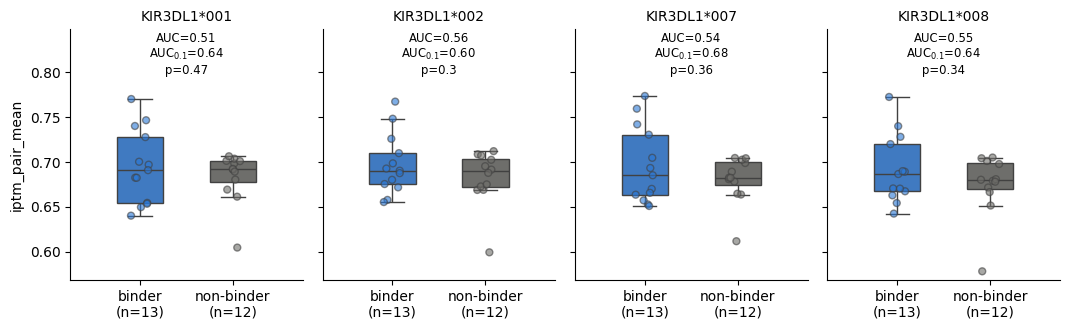

In [9]:
order = ["binder", "non-binder"]
pal   = {"binder": "#2a78d6", "non-binder": "#6f6e6a"}

kirs = sorted(bw.kir.unique())

fig, axes = plt.subplots(1, len(kirs), figsize=(2.7 * len(kirs), 3.4), sharey=True)

for i, (ax, k) in enumerate(zip(np.atleast_1d(axes), kirs)):
    d = bw[bw.kir == k]

    sns.boxplot(d, x="group", y=METRIC, order=order, hue="group", palette=pal,
                width=0.5, showfliers=False, legend=False, ax=ax)
    sns.stripplot(d, x="group", y=METRIC, order=order, hue="group", palette=pal,
                  jitter=True, alpha=0.6, marker="o", linewidth=1,
                  legend=False, ax=ax)

    ax.set_title(f"KIR3DL1{k}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel(METRIC if i == 0 else "")
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{g}\n(n={int((d.group == g).sum())})" for g in order])

    # AUC and standardized partial AUC (FPR<=0.1); binder = positive, higher ipTM = better
    y = d.group.eq("binder").astype(int)
    if y.nunique() < 2:
        auc = auc01 = p = np.nan
    else:
        auc   = roc_auc_score(y, d[METRIC])
        auc01 = roc_auc_score(y, d[METRIC], max_fpr=0.1)
        p     = mannwhitneyu(d.loc[y.eq(1), METRIC], d.loc[y.eq(0), METRIC],
                             alternative="greater").pvalue
    txt = f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}\np={p:.2g}"

    # axes coordinates, so the shared y-limit set below does not move the label
    ax.text(0.5, 0.99, txt, transform=ax.transAxes, ha="center", va="top", fontsize="small")

# one shared y-limit, with headroom for the annotations
ax0 = np.atleast_1d(axes)[0]
ymin, ymax = ax0.get_ylim()
ax0.set_ylim(ymin, ymax + 0.30 * (ymax - ymin))

sns.despine(fig=fig)
fig.tight_layout()

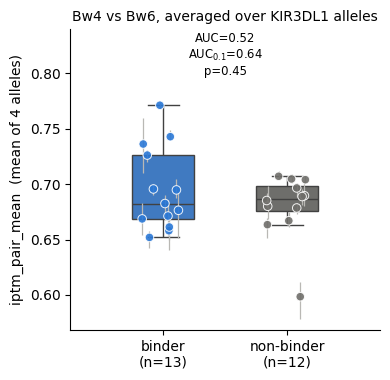

In [15]:
# one row per ligand: the mean over the 4 alleles, plus their spread
lig = bw.groupby(["MHC", "LIGAND_GROUP", "group"], as_index=False).agg(
    **{METRIC: (METRIC, "mean"),
       "lo":    (METRIC, "min"),
       "hi":    (METRIC, "max"),
       "n_kir": (METRIC, "size")})
assert lig.n_kir.eq(4).all(), "expected 4 alleles per ligand"

order  = ["binder", "non-binder"]
pal    = {"binder": "#2a78d6", "non-binder": "#6f6e6a"}
JITTER = 0.17

fig, ax = plt.subplots(figsize=(4.0, 3.9))

sns.boxplot(lig, x="group", y=METRIC, order=order, hue="group", palette=pal,
            width=0.5, showfliers=False, legend=False, ax=ax)

# the vertical line is the min-max across the 4 alleles, so what was averaged
# away stays visible rather than hidden
rng = np.random.default_rng(0)        # seeded, so the figure is reproducible
x = np.array([order.index(v) for v in lig.group], float)
x = x + rng.uniform(-JITTER, JITTER, len(x))
ax.vlines(x, lig.lo, lig.hi, color="#b9b8b4", linewidth=0.9, zorder=4)
ax.scatter(x, lig[METRIC], s=38, c=[pal[v] for v in lig.group],
           alpha=0.9, linewidth=0.7, edgecolor="white", zorder=5)

ax.set_xlabel("")
ax.set_ylabel(f"{METRIC}  (mean of 4 alleles)")
ax.set_title("Bw4 vs Bw6, averaged over KIR3DL1 alleles", fontsize=10)
ax.set_xlim(-0.75, 1.75)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{g}\n(n={int((lig.group == g).sum())})" for g in order])

y = lig.group.eq("binder").astype(int)
auc   = roc_auc_score(y, lig[METRIC])
auc01 = roc_auc_score(y, lig[METRIC], max_fpr=0.1)
p     = mannwhitneyu(lig.loc[y.eq(1), METRIC], lig.loc[y.eq(0), METRIC],
                     alternative="greater").pvalue
ax.text(0.5, 0.99, f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}\np={p:.2g}",
        transform=ax.transAxes, ha="center", va="top", fontsize="small")

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin, ymax + 0.26 * (ymax - ymin))

sns.despine(fig=fig)
fig.tight_layout()

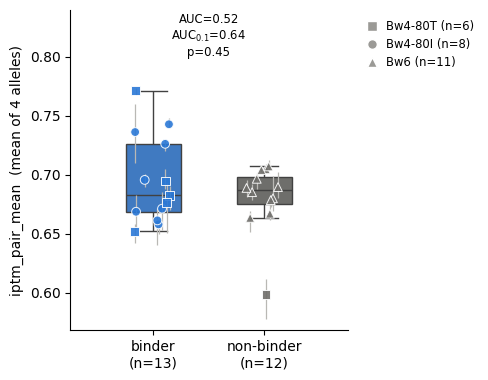

In [30]:
# --- the Bw4 subtype, read off the sequence rather than typed in ----------
# mature residue 80 sits in the Bw4/Bw6 epitope (77-83). The tab file holds the
# mature chain from residue 1, so position 80 is index 79.
REF_TAB = Path("/Users/roessner/Documents/PostDoc/Data/preMSA/Alleles_tab.txt")
ref_seq = dict(pd.read_csv(REF_TAB, sep="\t")[["Allele", "seq"]].itertuples(index=False))

bw["res80"]   = bw.MHC.map({m: ref_seq[m][79] for m in bw.MHC.unique()})
bw["subtype"] = np.where(bw.LIGAND_GROUP.eq("Bw6"), "Bw6", "Bw4-80" + bw.res80)

assert set(bw.loc[bw.LIGAND_GROUP.eq("Bw6"), "res80"]) == {"N"}, "Bw6 is not uniform at 80"
assert set(bw.loc[bw.LIGAND_GROUP.eq("Bw4"), "res80"]) <= {"T", "I"}, "unexpected Bw4 residue 80"

lig = bw.groupby(["MHC", "LIGAND_GROUP", "subtype", "group"], as_index=False).agg(
    **{METRIC: (METRIC, "mean"), "lo": (METRIC, "min"), "hi": (METRIC, "max"),
       "n_kir": (METRIC, "size")})
assert lig.n_kir.eq(4).all(), "expected 4 alleles per ligand"

order  = ["binder", "non-binder"]
pal    = {"binder": "#2a78d6", "non-binder": "#6f6e6a"}
MARKER = {"Bw4-80T": "s", "Bw4-80I": "o", "Bw6": "^"}
JITTER = 0.17

fig, ax = plt.subplots(figsize=(5, 3.9))

sns.boxplot(lig, x="group", y=METRIC, order=order, hue="group", palette=pal,
            width=0.5, showfliers=False, legend=False, ax=ax)

# colour still carries binder status; the marker carries the Bw4 subtype
rng = np.random.default_rng(0)        # seeded, so the figure is reproducible
for st, g in lig.groupby("subtype"):
    x = np.array([order.index(v) for v in g.group], float)
    x = x + rng.uniform(-JITTER, JITTER, len(x))
    ax.vlines(x, g.lo, g.hi, color="#b9b8b4", linewidth=0.9, zorder=4)
    ax.scatter(x, g[METRIC], marker=MARKER[st], s=40,
               c=[pal[v] for v in g.group],
               alpha=0.9, linewidth=0.7, edgecolor="white", zorder=5)

ax.set_xlabel("")
ax.set_ylabel(f"{METRIC}  (mean of 4 alleles)")
ax.set_xlim(-0.75, 1.75)
ax.set_xticks(range(len(order)))
ax.set_xticklabels([f"{g}\n(n={int((lig.group == g).sum())})" for g in order])

y = lig.group.eq("binder").astype(int)
auc   = roc_auc_score(y, lig[METRIC])
auc01 = roc_auc_score(y, lig[METRIC], max_fpr=0.1)
p     = mannwhitneyu(lig.loc[y.eq(1), METRIC], lig.loc[y.eq(0), METRIC],
                     alternative="greater").pvalue
ax.text(0.5, 0.99, f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}\np={p:.2g}",
        transform=ax.transAxes, ha="center", va="top", fontsize="small")

ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin, ymax + 0.26 * (ymax - ymin))

handles = [Line2D([], [], marker=MARKER[s], color="none", markerfacecolor="#9b9a96",
                  markeredgecolor="white", markersize=7,
                  label=f"{s} (n={int(lig.subtype.eq(s).sum())})")
           for s in ["Bw4-80T", "Bw4-80I", "Bw6"]]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
          frameon=False, fontsize="small", handletextpad=0.2, labelspacing=0.4)

sns.despine(fig=fig)
fig.tight_layout()

In [22]:
bw[bw['iptm_pair_mean'] < 0.63]

,ID,KIR,MHC,B2M,PEPTIDE,BINDING,LIGAND_GROUP,iptm_pair_mean,n_pred,kir,group,res80,subtype
13,kir_0014,KIR3DL1_001,HLA_B1302,B2M,,0,Bw4,0.6046,1,*001,non-binder,T,Bw4-80T
38,kir_0039,KIR3DL1_002,HLA_B1302,B2M,,0,Bw4,0.5993,1,*002,non-binder,T,Bw4-80T
63,kir_0064,KIR3DL1_007,HLA_B1302,B2M,,0,Bw4,0.6117,1,*007,non-binder,T,Bw4-80T
88,kir_0089,KIR3DL1_008,HLA_B1302,B2M,,0,Bw4,0.5781,1,*008,non-binder,T,Bw4-80T


In [20]:
lig[lig['iptm_pair_mean'] > 0.71]

,MHC,LIGAND_GROUP,group,iptm_pair_mean,lo,hi,n_kir
19,HLA_B4701,Bw4,binder,0.771100,0.7675,0.7738,4
20,HLA_B4901,Bw4,binder,0.736125,0.7100,0.7596,4
21,HLA_B5201,Bw4,binder,0.726150,0.7201,0.7306,4
22,HLA_B5301,Bw4,binder,0.742725,0.7401,0.7484,4


In [23]:
lst=['kir_0013', 'kir_0014', 'kir_0015']
bw[bw['ID'].isin(lst)]

,ID,KIR,MHC,B2M,PEPTIDE,BINDING,LIGAND_GROUP,iptm_pair_mean,n_pred,kir,group,res80,subtype
12,kir_0013,KIR3DL1_001,HLA_A3201,B2M,,1,Bw4,0.7004,1,*001,binder,I,Bw4-80I
13,kir_0014,KIR3DL1_001,HLA_B1302,B2M,,0,Bw4,0.6046,1,*001,non-binder,T,Bw4-80T
14,kir_0015,KIR3DL1_001,HLA_B0702,B2M,,0,Bw6,0.6986,1,*001,non-binder,N,Bw6


### Structural inspection

In [26]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from Bio.PDB import MMCIFIO, MMCIFParser, NeighborSearch

PROJ   = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
ESM    = PROJ / "esmfold2_bw4_bw6"
CUTOFF = 4.5          # heavy-atom distance, Angstrom

parser = MMCIFParser(QUIET=True)
labels = pd.read_csv(ESM / "kir_pmhc_names.csv", keep_default_na=False)

kir_hits, mhc_hits, pair_hits = Counter(), Counter(), Counter()
n_contacts = []

for i, r in enumerate(labels.itertuples(), 1):
    model = parser.get_structure(r.ID, ESM / "models" / f"{r.ID}.cif")[0]

    # the models carry no hydrogens, but filter anyway so the cutoff keeps
    # meaning what it says if that ever changes
    kir_atoms = [a for a in model["KIR"].get_atoms() if a.element != "H"]
    mhc_atoms = [a for a in model["MHC"].get_atoms() if a.element != "H"]

    ns = NeighborSearch(mhc_atoms)
    seen = set()
    for a in kir_atoms:
        for b in ns.search(a.coord, CUTOFF):
            seen.add((a.get_parent().id[1], b.get_parent().id[1]))

    # count each residue once per structure, however many partners it touches,
    # so the frequency is "in what fraction of models is this residue at the
    # interface" rather than a contact count
    for k in {k for k, _ in seen}:
        kir_hits[k] += 1
    for m in {m for _, m in seen}:
        mhc_hits[m] += 1
    for km in seen:
        pair_hits[km] += 1
    n_contacts.append(len(seen))

N = len(labels)
print(f"{N} structures, {np.mean(n_contacts):.1f} residue-residue contacts each "
      f"(min {min(n_contacts)}, max {max(n_contacts)})")

kir_freq = pd.Series({k: v / N for k, v in kir_hits.items()}, name="freq")
mhc_freq = pd.Series({m: v / N for m, v in mhc_hits.items()}, name="freq")

contacts = pd.DataFrame(
    [{"chain": "KIR", "resi": k, "n": v, "freq": v / N} for k, v in kir_hits.items()] +
    [{"chain": "MHC", "resi": m, "n": v, "freq": v / N} for m, v in mhc_hits.items()]
).sort_values(["chain", "freq"], ascending=[True, False])
contacts.to_csv(ESM / "kir_mhc_contact_frequency.csv", index=False)

print(f"{len(kir_freq)} KIR and {len(mhc_freq)} MHC residues contact at least once")
contacts.head(15)

100 structures, 41.4 residue-residue contacts each (min 34, max 51)
37 KIR and 30 MHC residues contact at least once


,chain,resi,n,freq
1,KIR,9,100,1.0
2,KIR,139,100,1.0
3,KIR,11,100,1.0
6,KIR,276,100,1.0
8,KIR,278,100,1.0
9,KIR,279,100,1.0
11,KIR,29,100,1.0
14,KIR,166,100,1.0
15,KIR,167,100,1.0
16,KIR,199,100,1.0


In [25]:
TEMPLATE = ESM / "models" / "kir_0001.cif"
OUT      = ESM / "kir_contacts.cif"

structure = parser.get_structure("kir_contacts", TEMPLATE)
model = structure[0]

# percent, so PyMOL's default b-factor ramp spans 0-100 like the pLDDT colouring
freq_by_chain = {"KIR": kir_freq, "MHC": mhc_freq}
for chain in model:
    freq = freq_by_chain.get(chain.id)          # B2M gets 0 throughout
    for res in chain:
        v = 0.0 if freq is None else 100.0 * float(freq.get(res.id[1], 0.0))
        for atom in res:
            atom.set_bfactor(v)

io = MMCIFIO()
io.set_structure(structure)
io.save(str(OUT))

# read it back: the file is the deliverable, so check the file, not the objects
check = parser.get_structure("check", OUT)[0]
got = {ch.id: {r.id[1]: next(iter(r)).get_bfactor() for r in ch} for ch in check}
assert all(abs(got["KIR"][k] - 100 * v) < 1e-6 for k, v in kir_freq.items())
assert all(abs(got["MHC"][m] - 100 * v) < 1e-6 for m, v in mhc_freq.items())
assert set(got["B2M"].values()) == {0.0}
print(f"wrote {OUT.relative_to(PROJ)}")

wrote esmfold2_bw4_bw6/kir_contacts.cif


In [32]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import PathPatch
from matplotlib.textpath import TextPath
from matplotlib.transforms import Affine2D

PROJ    = Path("/Users/roessner/Documents/PostDoc/Data/261105_kir_project")
ESM     = PROJ / "esmfold2_bw4_bw6"
REF_TAB = Path("/Users/roessner/Documents/PostDoc/Data/preMSA/Alleles_tab.txt")

# the four contact regions, as full spans; mature-chain numbering.
# 89-90 is kept apart from 72-84 rather than merged: it sits past the end of
# the alpha1 helix contact face.
REGIONS  = [(15, 21), (72, 84), (89, 90), (142, 151)]
FREQ_MIN = 0.5

ref_seq = dict(pd.read_csv(REF_TAB, sep="\t")[["Allele", "seq"]].itertuples(index=False))
labels  = pd.read_csv(ESM / "kir_pmhc_names.csv", keep_default_na=False)

# only ligands we actually folded, one row each
lig = labels[["MHC", "LIGAND_GROUP", "BINDING"]].drop_duplicates().copy()
lig["res80"] = lig.MHC.map(lambda m: ref_seq[m][79])

def group_of(r):
    if r.LIGAND_GROUP == "Bw6":
        return "Bw6"
    if r.BINDING == 0:
        return "Bw4 non-binder"
    return f"Bw4-80{r.res80} binder"

lig["lgroup"] = lig.apply(group_of, axis=1)

GROUPS = ["Bw4-80I binder", "Bw4-80T binder", "Bw4 non-binder", "Bw6"]
assert set(lig.lgroup) <= set(GROUPS), sorted(set(lig.lgroup) - set(GROUPS))

contacts = pd.read_csv(ESM / "kir_mhc_contact_frequency.csv")
hot = set(contacts.loc[contacts.chain.eq("MHC") & contacts.freq.gt(FREQ_MIN), "resi"])

print(lig.groupby("lgroup").MHC.size().to_string())
for a, b in REGIONS:
    print(f"  {a:3d}-{b:3d} ({b - a + 1:2d} aa)  contacting: {sorted(p for p in hot if a <= p <= b)}")

lgroup
Bw4 non-binder     1
Bw4-80I binder     8
Bw4-80T binder     5
Bw6               11
   15- 21 ( 7 aa)  contacting: [15, 16, 17, 18, 19, 21]
   72- 84 (13 aa)  contacting: [72, 76, 79, 80, 83, 84]
   89- 90 ( 2 aa)  contacting: [89, 90]
  142-151 (10 aa)  contacting: [142, 145, 146, 149, 150, 151]


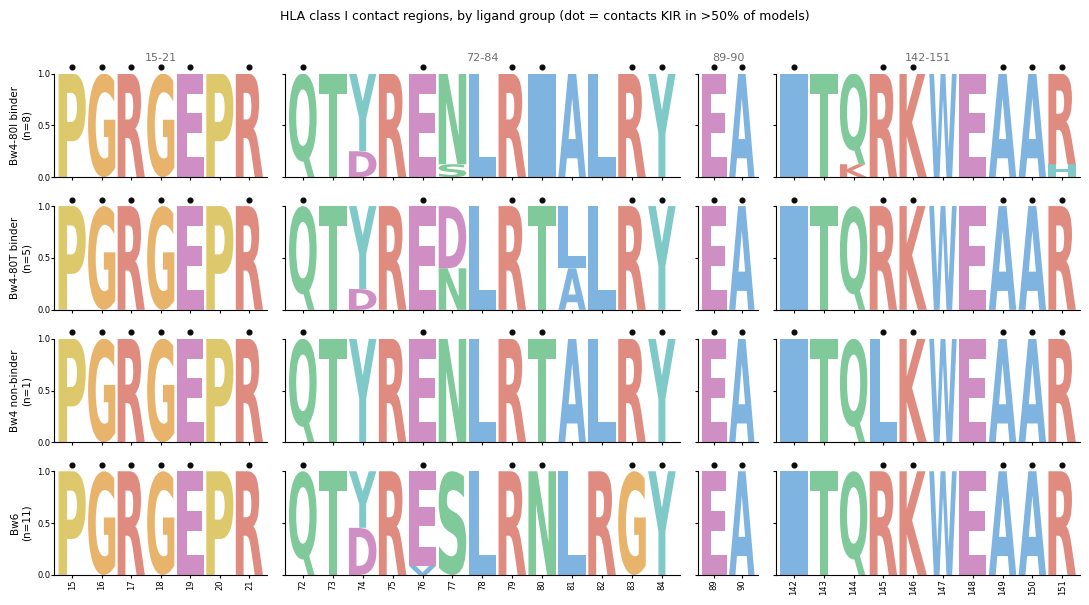

In [33]:
# physicochemical classes, same scheme as the alignment PDFs in Alignment.ipynb
CLASS_COLOR = {
    "hydrophobic": "#7fb3e0", "positive": "#e08b7f", "negative": "#d08fc4",
    "polar": "#7fc99a", "cysteine": "#e89ab4", "glycine": "#e8b36b",
    "proline": "#ddc96b", "aromatic": "#7fc9c9",
}
RESIDUE_CLASS = {r: c for c, rs in [
    ("hydrophobic", "AILMFWV"), ("positive", "KR"), ("negative", "DE"),
    ("polar", "NQST"), ("cysteine", "C"), ("glycine", "G"),
    ("proline", "P"), ("aromatic", "HY")] for r in rs}

INK, MUTED = "#0b0b0b", "#6f6e6a"
_FONT = matplotlib.font_manager.FontProperties(family="DejaVu Sans", weight="bold")


def _glyph(ax, letter, x, y0, height, width=0.92):
    """One letter, stretched to `height` and centred on column `x`."""
    tp = TextPath((0, 0), letter, size=1, prop=_FONT)
    bb = tp.get_extents()
    if bb.width == 0 or bb.height == 0:
        return
    # normalise the glyph to a unit box, then scale it into its stack slot
    t = (Affine2D()
         .translate(-bb.x0, -bb.y0)
         .scale(width / bb.width, height / bb.height)
         .translate(x - width / 2, y0))
    ax.add_patch(PathPatch(t.transform_path(tp),
                           facecolor=CLASS_COLOR.get(RESIDUE_CLASS.get(letter), "#b9b8b4"),
                           edgecolor="none"))


def logo(ax, seqs, start, hot, title=None, show_xticks=True):
    """Probability logo: each column sums to 1, letters stacked smallest first."""
    n, width = len(seqs), len(seqs[0])
    for j in range(width):
        counts = pd.Series([s[j] for s in seqs]).value_counts() / n
        y = 0.0
        for letter, frac in counts.sort_values().items():
            _glyph(ax, letter, j, y, frac)
            y += frac

    # a black dot marks a position that contacts KIR in >50% of the models
    pos = [j for j in range(width) if (start + j) in hot]
    ax.plot(pos, [1.06] * len(pos), "o", ms=3.4, color=INK, clip_on=False)

    ax.set_xlim(-0.6, width - 0.4)
    ax.set_ylim(0, 1)
    ax.set_xticks(range(width))
    ax.set_xticklabels([str(start + j) for j in range(width)] if show_xticks else [],
                       fontsize=6, rotation=90)
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(length=2, pad=1, labelsize=6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if title:
        ax.set_title(title, fontsize=8, color=MUTED, pad=9)


seqs_by_group = {g: [ref_seq[m] for m in sorted(lig.loc[lig.lgroup.eq(g), "MHC"])]
                 for g in GROUPS}

fig, axes = plt.subplots(
    len(GROUPS), len(REGIONS), figsize=(11.0, 1.5 * len(GROUPS)),
    gridspec_kw={"width_ratios": [b - a + 1 for a, b in REGIONS]}, squeeze=False)

for i, g in enumerate(GROUPS):
    for j, (a, b) in enumerate(REGIONS):
        ax = axes[i][j]
        logo(ax, [s[a - 1:b] for s in seqs_by_group[g]], a, hot,
             title=f"{a}-{b}" if i == 0 else None,
             show_xticks=(i == len(GROUPS) - 1))
        if j == 0:
            ax.set_ylabel(f"{g}\n(n={len(seqs_by_group[g])})", fontsize=7.5)
        else:
            ax.set_yticklabels([])

fig.suptitle("HLA class I contact regions, by ligand group "
             "(dot = contacts KIR in >50% of models)", fontsize=9, y=1.0)
fig.tight_layout()

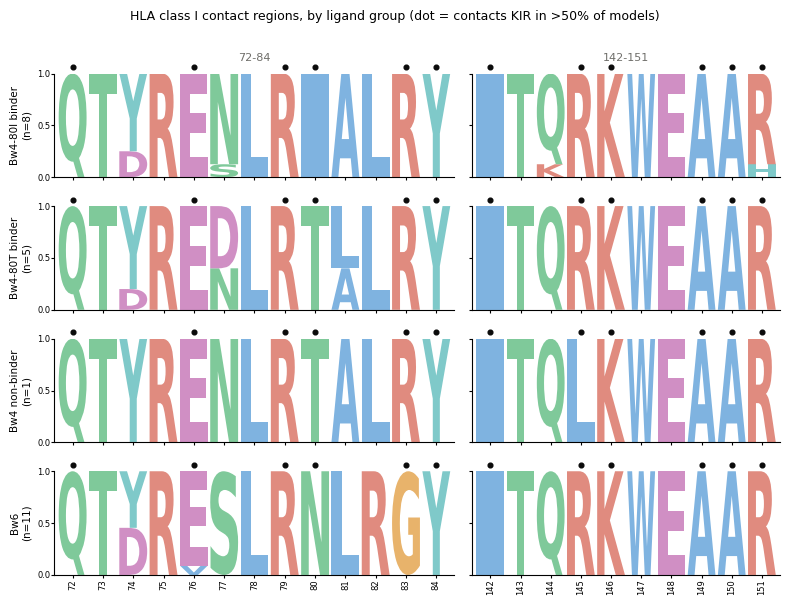

In [34]:
SHOW = [REGIONS[1], REGIONS[3]]          # 72-84 and 142-151 only

seqs_by_group = {g: [ref_seq[m] for m in sorted(lig.loc[lig.lgroup.eq(g), "MHC"])]
                 for g in GROUPS}

fig, axes = plt.subplots(
    len(GROUPS), len(SHOW), figsize=(8.0, 1.5 * len(GROUPS)),
    gridspec_kw={"width_ratios": [b - a + 1 for a, b in SHOW]}, squeeze=False)

for i, g in enumerate(GROUPS):
    for j, (a, b) in enumerate(SHOW):
        ax = axes[i][j]
        logo(ax, [s[a - 1:b] for s in seqs_by_group[g]], a, hot,
             title=f"{a}-{b}" if i == 0 else None,
             show_xticks=(i == len(GROUPS) - 1))
        if j == 0:
            ax.set_ylabel(f"{g}\n(n={len(seqs_by_group[g])})", fontsize=7.5)
        else:
            ax.set_yticklabels([])

fig.suptitle("HLA class I contact regions, by ligand group "
             "(dot = contacts KIR in >50% of models)", fontsize=9, y=1.0)
fig.tight_layout()